# 군집화 실습 (K-Means · DBSCAN)

카페: [군집화(DBSCAN)](https://cafe.naver.com/f-e/cafes/31780422/articles/623)  
세션 노트: [`session24.md`](../session24.md)

> **쉬운 말**  
> 앞부분은 **K-Means**(무리 개수를 미리 정하고 묶기)입니다.  
> 뒷부분은 **DBSCAN**(가까운 이웃이 많은 곳만 무리, 외딴 점은 잡음)입니다.  
> `eps` = 반경, `min_samples` = 최소 이웃 수입니다.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
#make_blobs : 가상의 클러스터를 생성해줌

In [3]:
centroid=[[3,1],[1,-1],[-3,-1]]

In [4]:
# 정답 클러스터 번호는 일부러 버림 -> 군집화는 비지도 학습이므로 정답을 알면안됨
X,_ = make_blobs(n_samples=1500, centers=centroid, cluster_std=0.5, random_state=1)
print(X)

[[-3.32691226 -0.82026947]
 [ 2.7877536   0.63423451]
 [-3.6918393  -1.43347761]
 ...
 [ 3.01093142  0.76566309]
 [ 1.27876632 -1.2213277 ]
 [ 3.42664109  0.93014413]]


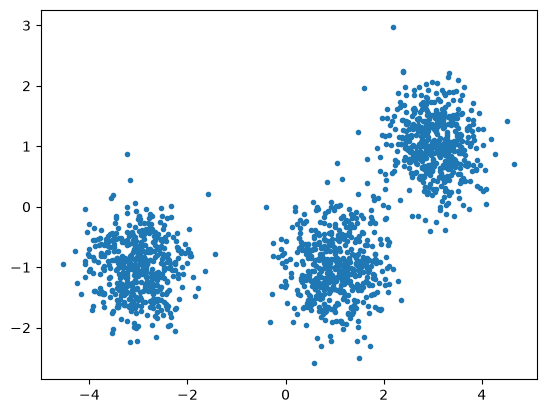

In [5]:
#1500개 점- 산점도 출력
# X[:,0] : x좌표
# X[:,1] : y좌표
plt.scatter(X[:,0], X[:,1], marker='.')

In [6]:
#클러스터 개수 지정 -> K-means가 데이터 나눌 그룹 수 설정
ncluster=3

In [7]:
#3개의 클러스터로 데이터 분할
k_means=KMeans(n_clusters=ncluster)

In [8]:
#모델 학습시킴(정답 y는 넣지 않는다)
k_means.fit(X);

In [9]:
#학습된 결과인 각 데이터의 그룹번호
k_means.labels_

array([1, 0, 1, ..., 0, 2, 0], shape=(1500,), dtype=int32)

In [10]:
#학습을 통해 찾아낸 최종 중심점 좌표
#1500개의 데이터를 반복해서 중심점을 계속 이동시키며 최종적으로 찾아낸 각 그룹의 중심점(대장) 좌표 
centers=k_means.cluster_centers_
centers

array([[ 3.03091263,  1.02108922],
       [-3.01381981, -1.00834877],
       [ 1.02065078, -0.982432  ]])

In [11]:
from matplotlib.colors import ListedColormap

color_bold=ListedColormap(['red','blue','green'])  #중심점
color_light=ListedColormap(['pink','skyblue','#42f584']) #데이터 점

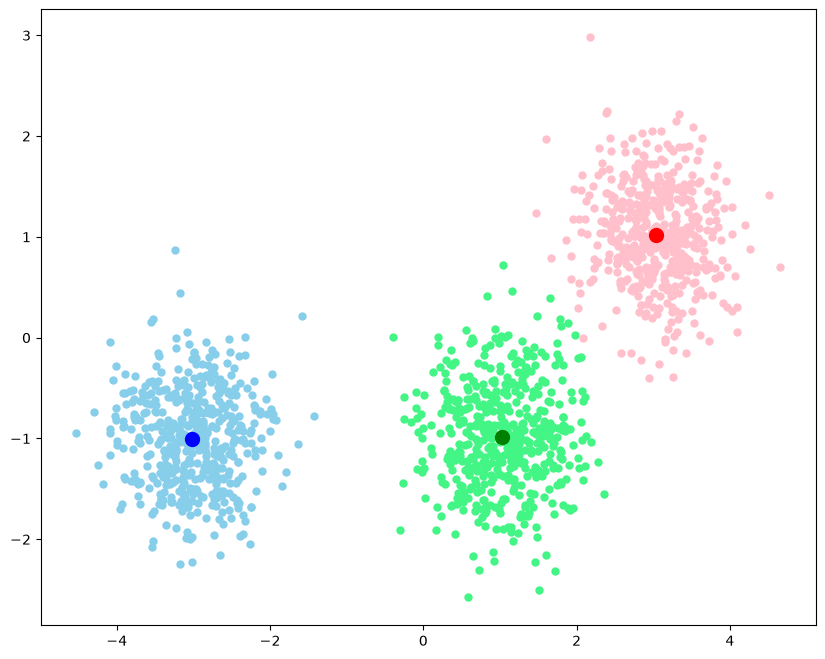

In [12]:
plt.figure(figsize=(10,8))

#i=0 -> 0번째 클러스터에 속하는 데이터만 골라서 x,y좌표러 점 출력
for i in range(ncluster):
    clusters=k_means.labels_ == i #[ True False  True ... False False False] -> 배열의 True위치에 해당하는 점만 남는다
    #0번 그룹 점들의 x,y좌표, 1번 그룹 점들의 x,y좌표 ...
    plt.plot(X[clusters, 0], X[clusters, 1], '.', c=color_light(i), markersize=10)
    plt.plot(centers[i, 0], centers[i, 1], 'o', c=color_bold(i), markersize=10)

In [13]:
# la=np.array([0,1,1,0,2,2])
# i=1

# result=la==i
# print(result)
# #[false, true, true, false, false, false]

In [14]:
# #6개 점 데이터
# X=[[1,2],
#    [5,6],
#    [1.5,5.6],
#    [8,8],
#    [8,4],
#    [2,5]]

# labels=[0,1,0,1,1,0] #0번,1번 그룹

# 0번 클러스터 -> [1,2], [1.5,5.6], [2,5]
# 1번 클러스터 -> [5,6], [8,8], [8,4]

# result=la==i 

# i=0 -> clusters=[true, false, true, false, false, true] => 뽑히는 점 [1,2], 
#                                                                     [1.5,5.6], 
#                                                                     [2,5]

# #X[clusters, 0] -> 1, 1.5, 2
# #X[clusters, 1] -> 2, 5.6, 5

In [15]:
from sklearn.cluster import DBSCAN
#클러스터 개수 미리 지정할 필요 없다 -> 밀집된 점을 클러스터로 그룹화
X1, _ = make_blobs(n_samples=500, centers=[[-3,-3]])
X2, _ = make_blobs(n_samples=500, centers=[[3,3]])
X3=np.random.rand(500,2)*3+4 #0~1사이 값 (4~7)
X4=np.random.randn(10,2)*3  #평균0 표준편차 1인 정규분포를 따르는 난수 20개를 만들어서 범위를 3배로 줌(약 -3~3)

print(X1.shape, X2.shape, X3.shape, X4.shape)

(500, 2) (500, 2) (500, 2) (10, 2)


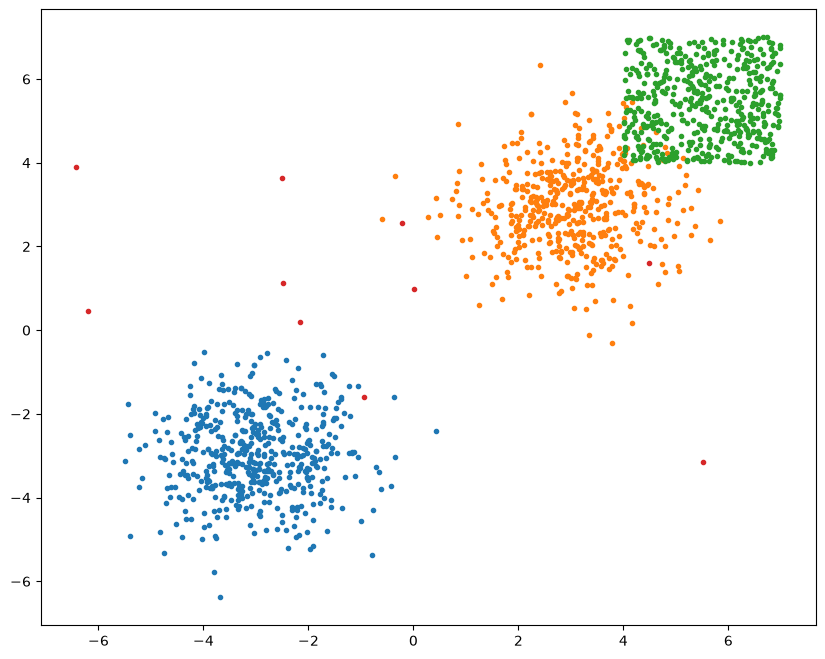

In [16]:
plt.figure(figsize=(10,8))
plt.scatter(X1[:,0], X1[:,1], marker='.')
plt.scatter(X2[:,0], X2[:,1], marker='.')
plt.scatter(X3[:,0], X3[:,1], marker='.')
plt.scatter(X4[:,0], X4[:,1], marker='.')

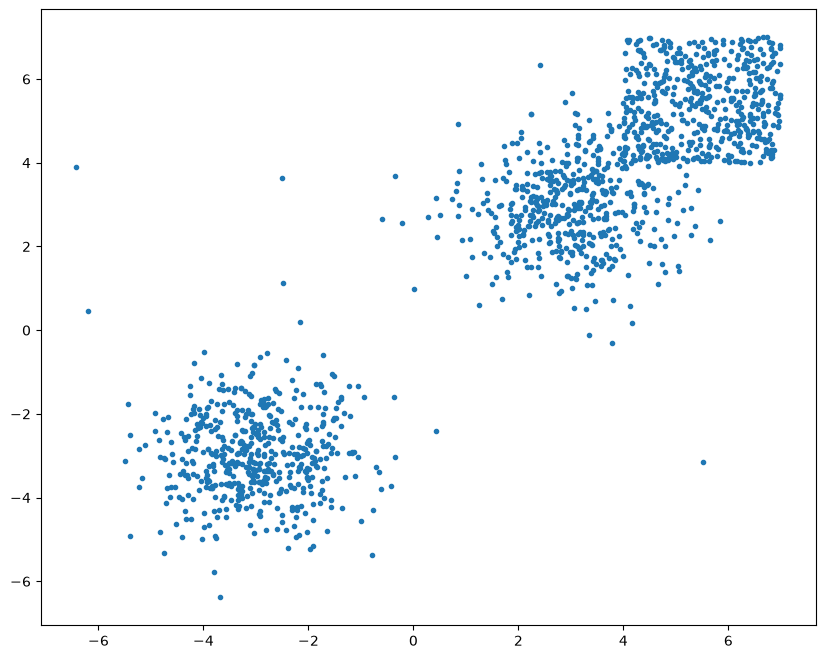

In [17]:
#네개 데이터셋 다 합치기
#데이터를 세로(수직)방향으로 쌓기(vertical stack)
#X : (1510, 2)
X=np.vstack([X1,X2,X3,X4])

plt.figure(figsize=(10,8))
plt.scatter(X[:,0], X[:,1], marker='.')

In [18]:
X

array([[-1.38546786, -1.60768559],
       [-2.35416431, -3.39021659],
       [-4.60810495, -3.74540808],
       ...,
       [-0.21288122,  2.56763106],
       [-6.19834278,  0.46243758],
       [-6.42820636,  3.89625326]], shape=(1510, 2))

In [19]:
epsilon=0.4 #반경거리
mininumPoints=8 #core point가 되기 위한 최소 점 개수

db=DBSCAN(eps=epsilon, min_samples=mininumPoints).fit(X);

In [20]:
#각 점이 어느그룹에 속하는지
labels=db.labels_
labels

array([ 0,  0,  0, ..., -1, -1, -1], shape=(1510,))

In [21]:
#핵심점 인덱스 배열
print(db.core_sample_indices_)

#핵심점의 개수 -> 1359개 /1510 ->90% - 10%는 noise + border point
print(db.core_sample_indices_.shape)

[   0    1    2 ... 1497 1498 1499]
(1334,)


In [22]:
#조건 까다로울 경우 (eps 작다 , min_sample은 크다) -> 핵심점 개수가 작다/노이즈가 증가할 수 있음
#조건 널널할 경우 (eps 크다, min_sample은 직다) -> 핵심점 개수가 크다/ 노이즈가 감소함 / 이상치를 못걸러냄